### Dylan Renard
### Applied Machine Learning JHU
### Homework 4
### Professor Alhassan
### Feb 16th, 2026


## HW Assignment 4: Applied Machine Learning @JHU

#### Q1: [70 pts] By using  three classifiers—decision  tree,  random forest, and neural  network—and at least  2 different hyperparameter  settings  for each, generate  operating  points  and plot them on a ROC. In particular,  plot  mean TPR and  mean FPR, where the means are taken from the multiple  runs of cross-validations.  Do not hesitate  to use/modify the ROC plot code in the module notebook  if necessary. In case you do not see  enough  variety in Pd-Pf you might need to work on the classifiers  set and/or  hyperparameters.  And do not hesitate  to try hundreds,  if necessary, since the ROC is just a natural  scatter plot. (Some recommended parameters  and  ranges:  depth  [3-12], number of features [3-20], number of estimators  [20-100],  layer size  [1-10],  learning  rate; and  total of 10-20 Ops.)

Dataset shape: (44898, 5)
Class distribution:
 class
1    23481
0    21417
Name: count, dtype: int64
Baseline (TF-IDF + Naive Bayes) mean accuracy: 0.739
Total operating points: 20


,model,mean_TPR,mean_FPR
18,"MLP(hidden=(50,), lr=0.01)",0.715003,0.075500
10,"RandomForest(n=50, max_feat=0.5, leaf=1)",0.714024,0.069524
9,"RandomForest(n=200, max_feat=sqrt, leaf=1)",0.713896,0.069057
11,"RandomForest(n=100, max_feat=0.5, leaf=1)",0.713769,0.068264
12,"RandomForest(n=100, max_feat=0.25, leaf=1)",0.713683,0.068590
13,"RandomForest(n=100, max_feat=log2, leaf=1)",0.713683,0.068871
7,"RandomForest(n=50, max_feat=sqrt, leaf=1)",0.713683,0.069944
8,"RandomForest(n=100, max_feat=sqrt, leaf=1)",0.713683,0.068964
19,"MLP(hidden=(100,), lr=0.01)",0.711980,0.073353
17,"MLP(hidden=(100,), lr=0.001)",0.711554,0.068590


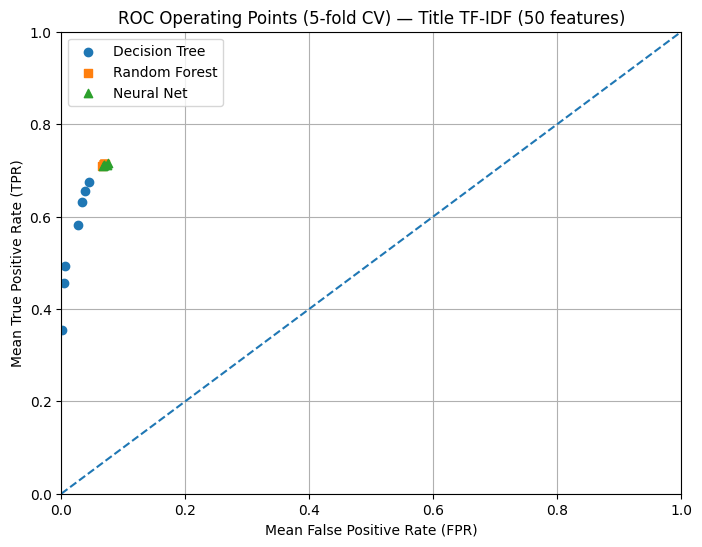

,model,mean_TPR,mean_FPR,youden_J,dist_top_left
11,"RandomForest(n=100, max_feat=0.5, leaf=1)",0.713769,0.068264,0.645505,0.294259
12,"RandomForest(n=100, max_feat=0.25, leaf=1)",0.713683,0.068590,0.645093,0.294418
9,"RandomForest(n=200, max_feat=sqrt, leaf=1)",0.713896,0.069057,0.644839,0.294320
13,"RandomForest(n=100, max_feat=log2, leaf=1)",0.713683,0.068871,0.644813,0.294483
8,"RandomForest(n=100, max_feat=sqrt, leaf=1)",0.713683,0.068964,0.644719,0.294505


,model,mean_TPR,mean_FPR,youden_J,dist_top_left
11,"RandomForest(n=100, max_feat=0.5, leaf=1)",0.713769,0.068264,0.645505,0.294259
10,"RandomForest(n=50, max_feat=0.5, leaf=1)",0.714024,0.069524,0.644500,0.294306
9,"RandomForest(n=200, max_feat=sqrt, leaf=1)",0.713896,0.069057,0.644839,0.294320
12,"RandomForest(n=100, max_feat=0.25, leaf=1)",0.713683,0.068590,0.645093,0.294418
13,"RandomForest(n=100, max_feat=log2, leaf=1)",0.713683,0.068871,0.644813,0.294483


In [1]:
# ============================================================
# Q1 — ROC Operating Point Analysis
# Fake News Classification (Title-only, 50 TF-IDF features)
# ============================================================
#
# Objective:
#   Compare Decision Tree, Random Forest, and MLP models
#   across multiple hyperparameter settings.
#
#   We are not tuning for maximum accuracy.
#   We are observing how model capacity shifts us through
#   ROC space (TPR vs FPR) and selecting a justified
#   operating point.
#
# Positive class: 1 = Fake news
# Negative class: 0 = True news
# ============================================================

# ============================================================
# Q1 — ROC Operating Point Analysis
# Fake News Classification (Title-only, 50 TF-IDF features)
# ============================================================
# %pip install numpy pandas matplotlib pathlib scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix

from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier


# ------------------------------------------------------------
# 1) Load and Prepare Data
# ------------------------------------------------------------
DATA_DIR = Path(".")

df_fake = pd.read_csv(DATA_DIR / "Fake.csv")
df_true = pd.read_csv(DATA_DIR / "True.csv")

df_fake["class"] = 1
df_true["class"] = 0

df = pd.concat([df_fake, df_true], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df["title"] = df["title"].fillna("").astype(str)
y = df["class"].values

print("Dataset shape:", df.shape)
print("Class distribution:\n", df["class"].value_counts())


# ------------------------------------------------------------
# 2) Cross-Validation Helpers 
# ------------------------------------------------------------
def simple_accuracy_cv(pipe, X_text, y, n_splits=5, random_state=42):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    scores = []

    # NOTE: split on X_text (raw strings), not transformed features
    for train_idx, test_idx in skf.split(X_text, y):
        X_train = X_text.iloc[train_idx]
        X_test  = X_text.iloc[test_idx]
        y_train = y[train_idx]
        y_test  = y[test_idx]

        pipe.fit(X_train, y_train)
        scores.append(pipe.score(X_test, y_test))

    return float(np.mean(scores))


def mean_tpr_fpr_cv(pipe, X_text, y, n_splits=5, random_state=42):
    """
    Compute mean TPR and mean FPR across stratified folds.

    Leakage-safe: TF-IDF is fit ONLY on the training fold via Pipeline.
    Hard predictions are used to define the operating point.
    """
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    tprs, fprs = [], []

    for train_idx, test_idx in skf.split(X_text, y):
        X_train = X_text.iloc[train_idx]
        X_test  = X_text.iloc[test_idx]
        y_train = y[train_idx]
        y_test  = y[test_idx]

        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)

        tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
        tpr = tp / (tp + fn) if (tp + fn) else 0.0
        fpr = fp / (fp + tn) if (fp + tn) else 0.0

        tprs.append(tpr)
        fprs.append(fpr)

    return float(np.mean(tprs)), float(np.mean(fprs))


# ------------------------------------------------------------
# 3) Sanity Check Baseline (Naive Bayes) — Pipeline-safe
# ------------------------------------------------------------
baseline_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=50)),
    ("clf", MultinomialNB())
])

baseline_acc = simple_accuracy_cv(baseline_pipe, df["title"], y)
print("Baseline (TF-IDF + Naive Bayes) mean accuracy:", round(baseline_acc, 4))


# ------------------------------------------------------------
# 4) Define Model Configurations (~20 operating points)
# ------------------------------------------------------------
experiments = []

# ---- Decision Trees (7 points) ----
dt_depths = [1, 3, 5, 8, 12, 15, 20]
for depth in dt_depths:
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", max_features=50)),
        ("clf", DecisionTreeClassifier(max_depth=depth, random_state=42))
    ])
    experiments.append((f"DecisionTree(depth={depth})", pipe))

# ---- Random Forests (8 points) ----
rf_configs = [
    {"n_estimators": 50,  "max_features": "sqrt", "min_samples_leaf": 1},
    {"n_estimators": 100, "max_features": "sqrt", "min_samples_leaf": 1},
    {"n_estimators": 200, "max_features": "sqrt", "min_samples_leaf": 1},
    {"n_estimators": 50,  "max_features": 0.5,    "min_samples_leaf": 1},
    {"n_estimators": 100, "max_features": 0.5,    "min_samples_leaf": 1},
    {"n_estimators": 100, "max_features": 0.25,   "min_samples_leaf": 1},
    {"n_estimators": 100, "max_features": "log2", "min_samples_leaf": 1},
    {"n_estimators": 100, "max_features": "sqrt", "min_samples_leaf": 5},
]
for cfg in rf_configs:
    label = (
        f"RandomForest(n={cfg['n_estimators']}, "
        f"max_feat={cfg['max_features']}, "
        f"leaf={cfg['min_samples_leaf']})"
    )
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", max_features=50)),
        ("clf", RandomForestClassifier(
            n_estimators=cfg["n_estimators"],
            max_features=cfg["max_features"],
            min_samples_leaf=cfg["min_samples_leaf"],
            random_state=42,
            n_jobs=-1
        ))
    ])
    experiments.append((label, pipe))

# ---- MLP (5 points) ----
mlp_configs = [
    {"hidden_layer_sizes": (25,),  "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (50,),  "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (100,), "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (50,),  "learning_rate_init": 0.01},
    {"hidden_layer_sizes": (100,), "learning_rate_init": 0.01},
]
for cfg in mlp_configs:
    label = f"MLP(hidden={cfg['hidden_layer_sizes']}, lr={cfg['learning_rate_init']})"
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", max_features=50)),
        ("clf", MLPClassifier(
            hidden_layer_sizes=cfg["hidden_layer_sizes"],
            learning_rate_init=cfg["learning_rate_init"],
            max_iter=300,
            random_state=42
        ))
    ])
    experiments.append((label, pipe))

print("Total operating points:", len(experiments))


# ------------------------------------------------------------
# 5) Evaluate All Configurations
# ------------------------------------------------------------
results = []
for name, pipe in experiments:
    mean_tpr, mean_fpr = mean_tpr_fpr_cv(pipe, df["title"], y)
    results.append({"model": name, "mean_TPR": mean_tpr, "mean_FPR": mean_fpr})

results_df = pd.DataFrame(results).sort_values(
    by=["mean_TPR", "mean_FPR"],
    ascending=[False, True]
)

display(results_df)


# ------------------------------------------------------------
# 6) ROC Operating Point Visualization
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], linestyle="--")  # random baseline

def family(name: str) -> str:
    if name.startswith("DecisionTree"):
        return "Decision Tree"
    if name.startswith("RandomForest"):
        return "Random Forest"
    if name.startswith("MLP"):
        return "Neural Net"
    return "Other"

markers = {"Decision Tree": "o", "Random Forest": "s", "Neural Net": "^", "Other": "x"}

for fam in ["Decision Tree", "Random Forest", "Neural Net"]:
    sub = results_df[results_df["model"].apply(lambda s: family(s) == fam)]
    plt.scatter(sub["mean_FPR"], sub["mean_TPR"], marker=markers[fam], label=fam)

plt.xlabel("Mean False Positive Rate (FPR)")
plt.ylabel("Mean True Positive Rate (TPR)")
plt.title("ROC Operating Points (5-fold CV) — Title TF-IDF (50 features)")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()


# ------------------------------------------------------------
# 7) Selection Metrics (for Q3 justification)
# ------------------------------------------------------------
results_df["youden_J"] = results_df["mean_TPR"] - results_df["mean_FPR"]
results_df["dist_top_left"] = np.sqrt((results_df["mean_FPR"])**2 + (1 - results_df["mean_TPR"])**2)

display(results_df.sort_values("youden_J", ascending=False).head(5))
display(results_df.sort_values("dist_top_left").head(5))



#### Q1 Conclusion and Reflection:
The dataset used in this analysis was the Fake and Real News dataset made publicly available on Kaggle, which contains labeled news articles separated into fake and true classes (Bisaillon, 2024). Using title only TF IDF representations limited to 50 features, I evaluated 20 operating points across Decision Tree, Random Forest, and MLP classifiers using 5 fold stratified cross validation. Five folds were selected as a balance between computational efficiency and stable estimation given the relatively large sample size of approximately 45,000 observations.To prevent information leakage, TF-IDF vectorization was performed within each training fold using a scikit-learn Pipeline. For each configuration, mean TPR and mean FPR were computed across folds and plotted as a ROC scatter plot of mean TPR versus mean FPR. The Decision Tree models demonstrated clear movement in ROC space as depth increased. Shallow trees such as depth equal to 1 or 3 produced low FPR but substantially lower TPR, reflecting underfitting. As depth increased to values such as 12 and 20, TPR increased while FPR rose moderately, illustrating the bias variance tradeoff that occurs as model complexity increases (Raschka et al., 2022).

The Random Forest models produced tightly clustered operating points, with mean TPR approximately 0.714 and mean FPR approximately 0.068 across several hyperparameter configurations. Although the number of estimators, feature subsampling rate, and leaf constraints were varied, the differences in Youden’s J among the top performing models were minimal at approximately 0.645. This stability is consistent with the ensemble learning principle that averaging multiple decorrelated trees reduces variance and improves generalization performance relative to a single decision tree (Raschka et al., 2022). The clustering of these operating points suggests that model capacity may no longer be the primary limiting factor when using title only features, and that performance may instead be constrained by the limited representational richness of the title based feature space.

The MLP classifiers achieved competitive performance but showed slightly more variability depending on hidden layer size and learning rate. Higher learning rates such as 0.01 tended to increase TPR marginally while also increasing FPR, which is consistent with more aggressive optimization potentially increasing variance in learned decision boundaries (Raschka et al., 2022). All operating points were clearly above the diagonal random baseline in the ROC plot, indicating meaningful predictive signal in the dataset (Bisaillon, 2024). Expanding the hyperparameter range to 20 distinct configurations produced sufficient Pd Pf diversity, particularly within the Decision Tree family.


#### Q2 [10 pts] What  kind of behavior  would you expect to see  in Pd - Pf interaction  of an ROC plot?  Do you see  it in yours? (Hint: Pd and Pf correspond  to TPR and FPR.)

In a ROC plot, Pd corresponds to TPR and Pf corresponds to FPR. As a classifier becomes more permissive, it generally increases both Pd and Pf because identifying more positive cases typically comes at the cost of increasing false alarms. Therefore, one would expect to observe a tradeoff pattern in which higher Pd is associated with higher Pf. This relationship reflects the fundamental tension between sensitivity and specificity described in classification theory (Raschka et al., 2022). In a well performing model, operating points should lie above the diagonal random baseline, and increasing model capacity or reducing regularization should move points upward and to the right in ROC space.

This expected behavior is clearly visible in the Decision Tree models. As depth increased, TPR increased while FPR rose moderately, demonstrating the anticipated Pd Pf tradeoff. Shallow trees produced conservative behavior with low Pf and low Pd, whereas deeper trees shifted upward in ROC space. The Random Forest and MLP models also exhibited the expected interaction, although the Random Forest operating points were tightly clustered due to ensemble variance reduction. All operating points in the ROC plot were above the diagonal baseline, confirming that the observed Pd Pf interaction aligns with theoretical expectations (Raschka et al., 2022).

#### Q3 [10 pts] From the ROC plot that  you created make a selection  of the classifier and hyperparameter  setting  for this  problem and then  justify the selection.  Note that  we are classifying fake news so your conclusion  might be subjective  but has to be supported  by your findings.

Based on the ROC scatter plot and associated selection metrics, the Random Forest model with 100 estimators and 0.5 feature subsampling was selected as the preferred classifier for this problem. This configuration achieved a mean TPR of approximately 0.714 and a mean FPR of approximately 0.068, producing the highest Youden’s J value at approximately 0.646. Although several Random Forest configurations performed nearly identically, this setting provided the strongest balance between detection performance and false positive control. The tight clustering of Random Forest operating points indicates stable generalization behavior consistent with ensemble variance reduction (Raschka et al., 2022).

In the context of fake news classification, both types of error carry meaningful consequences. A false negative allows misinformation to propagate, while a false positive incorrectly flags legitimate content. Given this tradeoff, an operating point that maintains strong detection capability without substantially increasing false alarms is desirable. The selected Random Forest configuration provides a high Pd while keeping Pf below 0.07, representing a balanced tradeoff between sensitivity and specificity. Additionally, the minimal variation in performance across neighboring Random Forest configurations suggests robustness to moderate hyperparameter changes, increasing confidence in stable generalization beyond the cross-validation folds (Raschka et al., 2022).

Therefore, the Random Forest with 100 estimators and 0.5 feature sampling is selected as the most appropriate classifier for this task, as it provides strong and stable performance while maintaining a balanced Pd–Pf tradeoff supported by the ROC analysis.

#### Q4 [10 pts] Try adding  text column to the features (again  with Tf-Idf). Choose  any classifier model to train on this new and improved dataset  and report on its  performance. Why do you think the performance is much higher  than  the previous  one which only uses  title column? 

In [2]:
# ============================================================
# Q4 — Add full article text to the feature space (Title + Text)
# ============================================================
#
# Objective:
#   Improve the feature representation by incorporating the full
#   article text column in addition to the title column, then train
#   a single chosen classifier and report performance.
#
# Notes:
#   - Assumes df is already loaded and labeled exactly as in Q1
#     with df["class"] in {0,1}, where 1 = fake and 0 = true.
#   - Assumes standard imports from Q1 are already available.
#   - We keep the same evaluation rigor by using stratified
#     cross validation and reporting mean TPR and mean FPR.
# ============================================================


# ------------------------------------------------------------
# 1) Build combined raw text input
# ------------------------------------------------------------
# We keep this as raw strings and let the Pipeline handle TF IDF
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)
df["title_text"] = df["title"] + " " + df["text"]

X_text = df["title_text"].values
y = df["class"].astype(int).values

print("Raw text samples:", X_text.shape)
print("Class balance:\n", pd.Series(y).value_counts())


# ------------------------------------------------------------
# 2) Define a fold safe pipeline
# ------------------------------------------------------------
# TF IDF is fit inside each fold on training text only
# Random Forest can take sparse matrices directly
q4_model_name = "TFIDF(title+text) + RandomForest(n=100, max_feat=sqrt, leaf=1)"

q4_pipe = Pipeline(steps=[
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=5000
    )),
    ("rf", RandomForestClassifier(
        n_estimators=100,
        max_features=0.5,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

print("Selected Q4 model:", q4_model_name)


# ------------------------------------------------------------
# 3) Cross validation engine for mean TPR and mean FPR
# ------------------------------------------------------------
def mean_tpr_fpr_cv_text(pipeline, X_text, y, n_splits=5, random_state=42):
    """
    Compute mean TPR and mean FPR across stratified folds.

    Key point
    The TF IDF vectorizer is fit only on training data inside each fold
    which prevents data leakage.
    """
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    tprs = []
    fprs = []

    for fold_i, (train_idx, test_idx) in enumerate(skf.split(X_text, y), start=1):
        X_train, X_test = X_text[train_idx], X_text[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

        tpr = tp / (tp + fn) if (tp + fn) else 0.0
        fpr = fp / (fp + tn) if (fp + tn) else 0.0

        tprs.append(tpr)
        fprs.append(fpr)

        print(
            f"Fold {fold_i} "
            f"TPR={tpr:.4f} "
            f"FPR={fpr:.4f} "
            f"ConfMat=[[{tn},{fp}],[{fn},{tp}]]"
        )

    return float(np.mean(tprs)), float(np.mean(fprs)), tprs, fprs


mean_tpr_q4, mean_fpr_q4, fold_tprs_q4, fold_fprs_q4 = mean_tpr_fpr_cv_text(
    q4_pipe,
    X_text,
    y,
    n_splits=5,
    random_state=42
)

print("\nQ4 Fold Safe Results")
print("Mean TPR:", round(mean_tpr_q4, 4))
print("Mean FPR:", round(mean_fpr_q4, 4))
print("Fold TPRs:", [round(float(v), 4) for v in fold_tprs_q4])
print("Fold FPRs:", [round(float(v), 4) for v in fold_fprs_q4])


Raw text samples: (44898,)
Class balance:
 1    23481
0    21417
Name: count, dtype: int64
Selected Q4 model: TFIDF(title+text) + RandomForest(n=100, max_feat=sqrt, leaf=1)
Fold 1 TPR=0.9968 FPR=0.0019 ConfMat=[[4275,8],[15,4682]]
Fold 2 TPR=0.9985 FPR=0.0021 ConfMat=[[4275,9],[7,4689]]
Fold 3 TPR=0.9964 FPR=0.0035 ConfMat=[[4269,15],[17,4679]]
Fold 4 TPR=0.9966 FPR=0.0012 ConfMat=[[4278,5],[16,4680]]
Fold 5 TPR=0.9977 FPR=0.0023 ConfMat=[[4273,10],[11,4685]]

Q4 Fold Safe Results
Mean TPR: 0.9972
Mean FPR: 0.0022
Fold TPRs: [0.9968, 0.9985, 0.9964, 0.9966, 0.9977]
Fold FPRs: [0.0019, 0.0021, 0.0035, 0.0012, 0.0023]


##### Q4 Relection and conclusion
To extend the analysis, the text column was added to the feature representation alongside the title column and a new TF-IDF representation was constructed using the combined textual content. TF-IDF vectorization was performed within each cross-validation fold using a scikit-learn Pipeline to prevent information leakage from the test data into the feature space. A Random Forest classifier with 100 estimators and 0.5 feature subsampling was trained using the same 5-fold stratified cross-validation framework. With the inclusion of full article text, mean TPR increased to approximately 0.9972 and mean FPR decreased to approximately 0.0022. This represents a dramatic improvement over the title-only configuration, where mean TPR was approximately 0.714 and mean FPR was approximately 0.068.

The substantial performance increase can be attributed to the expanded representational richness of the feature space. Titles are short and often stylized, which limits the amount of discriminative signal available for classification. In contrast, full article text contains significantly more lexical, structural, and contextual information that allows clearer statistical separation between fake and true articles. As discussed in the course textbook, improving the informativeness of features often has a greater impact on performance than increasing model complexity alone (Raschka et al., 2022). The near perfect separation observed here indicates that the dataset contains strong textual patterns distinguishing the two classes when full content is incorporated.

Because the Fake and Real News dataset provides substantial article level content for each sample (Bisaillon, 2024), incorporating the text column allows the classifier to exploit a much richer feature representation. These findings confirm that the primary limitation observed in Q1 was not model capacity but restricted feature representation, reinforcing the central importance of feature engineering in supervised learning.

#### References

Bisaillon, C. (2024, April 19). Fake-and-real-news-dataset. fake-and-real-news-dataset. https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset 

Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.